# Building a gene-expression atlas with pyanimalprocessing

<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); color: white; padding: 1.2em 1.8em; border-radius: 10px; margin-bottom: 1em;">

<p style="margin: 0 0 0.2em 0; font-weight: 300; font-size: 0.95em; letter-spacing: 0.05em; opacity: 0.85;">BELLAICHE LAB — Institut Curie</p>
<p style="margin: 0; font-size: 0.82em; opacity: 0.7;">Adrien Leroy, Eric van Leen, Maria Balakireva, Lale Alpar, Fabian Gärtner, Rémi Pigache, Isabelle Gaugué, Stéphane Pelletier, Mehdi Ech-Chouini, Julien Delpierre, Stéphane Rigaud, Floris Bosveld, Lorette Noiret, Yohanns Bellaïche</p>
<p style="margin: 0.1em 0 0 0; font-size: 0.75em; opacity: 0.5;">August 2026</p>

</div>

In [Leroy, van Leen et al., Cell Reports (2026)](https://doi.org/10.5281/zenodo.19633285), a genome-wide spatial transcriptome is reconstructed by mapping scRNA-seq cells onto a **reference atlas**: per-gene expression patterns of fixed, stained nota averaged onto one common spatial grid. This notebook builds a miniature version of that atlas.

We will learn how to:

1. **Load fixed-image animals**, one zarr store per sample, created from the microscope TIFs with `instantiate_animal`
2. **Register every sample on shared anatomical landmarks** with napari (`space_registrate`)
3. **Build a reference archetype**, a synthetic animal defining the common frame and its 40 µm grid
4. **Rescale every sample onto the archetype** (`generate_common_grid`, the MATLAB-faithful `xyscale_translation` transform)
5. **Measure per-box expression** (`analyze_labels` on grid compartments) and average it **per gene across samples** (`average_over_animals`)
6. **Normalize the per-gene maps and assemble the final atlas**; one table over the boxes covered by every gene

The complete workflow, including [vgep](https://github.com/BellaicheLab/vgep) for transcriptome reconstruction, is documented in the [atlas walkthrough](../docs/guides/atlas_pipeline.md); the reconstruction itself is demonstrated in [morphodomains notebook 02](https://github.com/BellaicheLab/morphodomains).

## 1. Setup

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import zarr
import napari
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from qtpy.QtWidgets import QDockWidget

from tutorial_setup import stage_atlas_samples
from pyanimalprocessing.preprocessing import instantiate_animal, space_registrate
from pyanimalprocessing.rescaling.registration import generate_archetype, generate_common_grid
from pyanimalprocessing.analyze_labels import analyze_labels
from pyanimalprocessing.average_over_time import average_over_time
from pyanimalprocessing.average_over_animals import average_over_animals

import os
DATA_ROOT = Path(os.environ.get("MORPHODOMAINS_DATA", str(Path("..").resolve().parents[1])))
ATLAS_STORES = DATA_ROOT / "data/zarr_atlases"
ATLAS_TXT = DATA_ROOT / "data/morphology/atlas_validation.txt"
MACROCHAETE = DATA_ROOT / "data/morphology/macrochaete.csv"

N_GENES = 10
SAMPLES_PER_GENE = 3

WORK = Path("_work") / "atlas_demo"
(WORK / "stores").mkdir(parents=True, exist_ok=True)
MICROSCOPY, GENES = stage_atlas_samples(ATLAS_STORES, WORK, ATLAS_TXT, N_GENES, SAMPLES_PER_GENE)
print(GENES)

['Pvr', 'wg', 'hth', 'bi', 'crp', 'slf', 'C15', 'cda4', 'Diap1', 'mirr']


## 2. The atlas samples

Each stained sample comes off the microscope as one TIF per channel, the E-cadherin reference (`Cad`) and the gene readout (`Gene`), plus a tissue mask, and becomes a **fixed-image animal**: a single-frame, two-channel store assembled by `instantiate_animal`. In this tutorial the TIFs are organised in one folder per sample, grouped by gene:

```text
microscopy/
├── Pvr/
│   ├── 200531_Pvr_15APF_s1l/
│   │   ├── raw/     c1_0001.tif (Cad), c2_0001.tif (Gene)
│   │   └── mask/    mask_0001.tif
│   ├── 200531_Pvr_15APF_s1r/
│   └── 200531_Pvr_15APF_s2l/
├── wg/
│   └── ...
└── ...
```

`instantiate_animal` assembles each sample from its folder:

In [2]:
animals_by_gene = {gene: [] for gene in GENES}
for gene in GENES:
    for sample_dir in sorted((MICROSCOPY / gene).iterdir()):
        animal = instantiate_animal(
            output_zarr=str(WORK / "stores" / f"{sample_dir.name}.zarr"),
            raw_image_2d=str(sample_dir / "raw"), raw_image_2d_order="ct(yx)",
            mask_2d=str(sample_dir / "mask"), mask_2d_order="tyx",
            channel_names=["Cad", "Gene"],
            dt=5.0, temperature=25.0, time_ref="17h00", frame_ref=0,
        )
        animal.attrs["gene"] = gene
        animals_by_gene[gene].append(animal)

all_animals = [a for group in animals_by_gene.values() for a in group]
print({g: len(v) for g, v in animals_by_gene.items()})

{'Pvr': 3, 'wg': 3, 'hth': 3, 'bi': 3, 'crp': 3, 'slf': 3, 'C15': 3, 'cda4': 3, 'Diap1': 3, 'mirr': 3}


## 3. Space registration

Cross-sample comparison rests on shared anatomy: on every sample, the **8 macrochaetae** (stereotyped sensory bristles) are clicked in a fixed order, plus the neck as a ninth landmark. `space_registrate` opens the interactive napari tool: click the landmarks in order, then close the viewer and the clicks are written under `SPACE_REGISTRATION/atlas_sr`. The [space registration guide](../docs/guides/space_registration.md) shows the anatomy, and the MATLAB equivalent if you would rather use MATLAB.

In [3]:
unregistered = [a for a in all_animals
                if "SPACE_REGISTRATION" not in a or "atlas_sr" not in a["SPACE_REGISTRATION"]]
print(f"{len(unregistered)} samples left to click")
if unregistered:
    # click the landmarks, close the viewer to save, then re-run this cell
    space_registrate(unregistered[0], registration_name="atlas_sr")

0 samples left to click


Re-opening a registered sample shows its clicks, for review or editing :

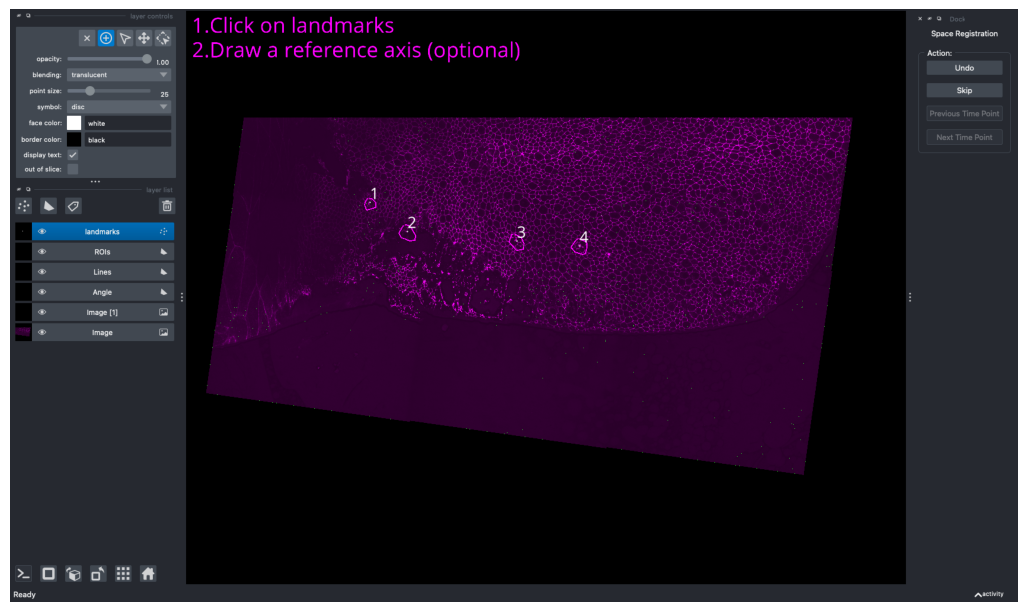

In [4]:
viewer = napari.Viewer()
viewer.window.resize(1700, 1000)
space_registrate(animals_by_gene[GENES[0]][0], registration_name="atlas_sr", viewer=viewer)
viewer.window._qt_window.findChildren(QDockWidget)[-1].setVisible(True)  # dock starts hidden off-screen
viewer.reset_view()

plt.figure(figsize=(13, 7.7))
plt.imshow(viewer.screenshot(canvas_only=False))
plt.axis("off")
plt.show()
viewer.close()

A look at the gene channel of three samples, with each sample's own clicked macrochaetae:

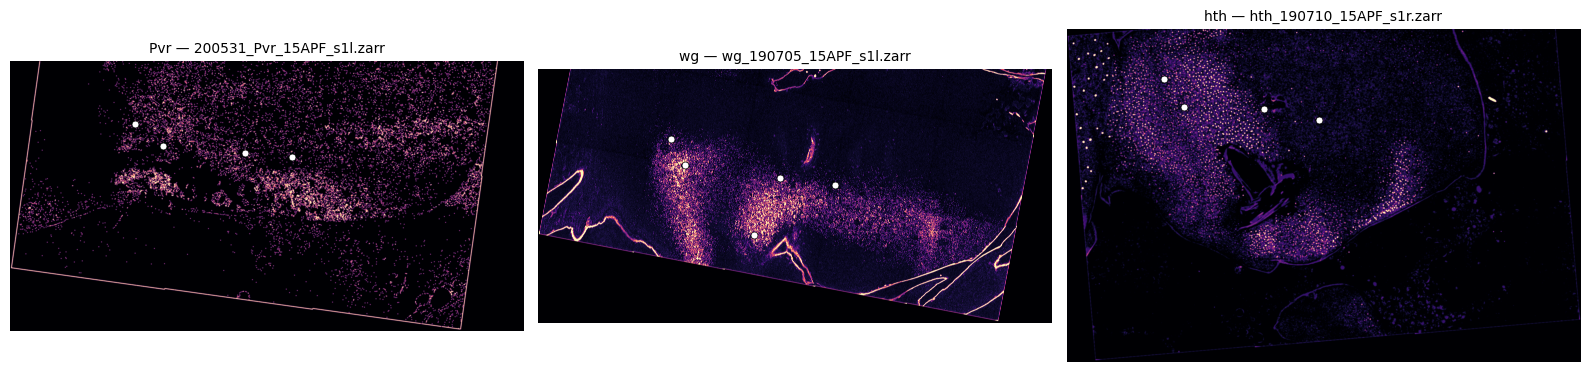

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, gene in zip(axes, GENES[:3]):
    a = animals_by_gene[gene][0]
    img = gaussian_filter(np.asarray(a["IMAGE/D2/raw"][0, 1], float), 4)
    lm = a["SPACE_REGISTRATION/atlas_sr/landmarks"][:8, 1:]
    ax.imshow(img, cmap="magma", vmax=np.percentile(img[a["IMAGE/D2/mask"][0]], 99.5))
    ax.scatter(lm[:, 1], lm[:, 0], s=25, facecolor="white", edgecolor="black", lw=0.5)
    ax.set_title(f"{gene} — {a.attrs['name']}", fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 4. The reference archetype

The **archetype** is a synthetic reference animal: it carries only landmarks (in microns) and a fixed grid frame. We use the canonical archetype of the published atlas, its 8 macrochaetae and the frame that yields a 40 µm grid (overlap 0.5) of 67 × 40 boxes. You can also generate an archetype directly from multiple images instead of manually specifying coordinates.

In [6]:
ARCHETYPE_YX = [
    [-37.8125145, -109.1786175],
    [10.9751895, -87.3504135],
    [9.0800595, 62.7462045],
    [17.7572655, 133.7828265],
    [103.2276555, 35.0425305],
    [173.6478135, 55.1225925],
    [199.5614415, 153.7899345],
    [200.6938215, 80.0648145],
]
GRID_FRAME = (-190.0, 610.0, -470.0, 870.0)   # y_min, y_max, x_min, x_max (um)

archetype = generate_archetype(
    output_path=str(WORK / "gene_archetype.zarr"),
    landmarks=ARCHETYPE_YX, grid_frame=GRID_FRAME, n_macros=8,
    registration_name="atlas_sr", name="gene_archetype",
)

## 5. One common grid for every sample

`generate_common_grid` fits, per sample, the transform mapping its landmarks onto the archetype's. `xyscale_translation` (independent x/y scaling + translation, no rotation) is the transform the MATLAB pipeline uses. Because the archetype carries a stored frame, every gene ends up on the *identical* grid.

In [7]:
generate_common_grid(
    all_animals, boxsize=[40, 40], overlap=0.5,
    registration_name="atlas_sr", reference_animal=archetype,
    transform_type="xyscale_translation", grid_type="eulerian",
)


Generating Grids objects and rescaling:   0%|          | 0/30 [00:00<?, ?animal/s]


Generating Grids objects and rescaling:   7%|▋         | 2/30 [00:00<00:01, 18.42animal/s]


Generating Grids objects and rescaling:  17%|█▋        | 5/30 [00:00<00:01, 22.21animal/s]


Generating Grids objects and rescaling:  27%|██▋       | 8/30 [00:00<00:00, 22.82animal/s]


Generating Grids objects and rescaling:  43%|████▎     | 13/30 [00:00<00:00, 32.00animal/s]

...

Time taken for mirr_150313_2l.zarr: 2.0353047847747803 seconds



  0%|          | 0/1 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00,  5.69it/s]


100%|██████████| 1/1 [00:00<00:00,  5.68it/s]

Time taken for mirr_161116_3l.zarr: 2.7305831909179688 seconds


## 6. Per-box expression, per-gene averages

Per-box expression is simply the mean gene-channel intensity over each grid compartment. The single fixed frame is then time-averaged as a one-frame timelapse at 17 hAPF (the standard backup structure), and `average_over_animals` produces one store per gene, in which every quantity carries a trailing animal axis. Index 0 is the weighted mean, 1..N the individual samples.

In [8]:
analyze_labels(
    all_animals, analysis_type="eulerian", intensity_image="raw",
    properties=["intensity_mean"], dimension="D2",
)

average_over_time(
    all_animals, properties=["intensity_mean"], grid_type="eulerian",
    averaged_type=None, time_start="17h00", time_stop="17h05",
    time_window="00h01", time_step=5,
)

(WORK / "aoa").mkdir(exist_ok=True)
backups = {}
for gene, group in animals_by_gene.items():
    out = WORK / "aoa" / f"{gene}.zarr"
    average_over_animals(group, output_path=str(out), animal_reference=group[0], rescale="Full")
    backups[gene] = zarr.open(str(out), mode="r")["EULERIAN/D2/default"]


Analyzing frames:   0%|          | 0/1 [00:00<?, ?it/s]


Analyzing frames: 100%|██████████| 1/1 [00:15<00:00, 15.01s/it]


Analyzing frames: 100%|██████████| 1/1 [00:15<00:00, 15.03s/it]


Analyzing frames:   0%|          | 0/1 [00:00<?, ?it/s]


Analyzing frames: 100%|██████████| 1/1 [00:15<00:00, 15.45s/it]

...


Analyzing frames: 100%|██████████| 1/1 [00:03<00:00,  3.31s/it]


Analyzing frames: 100%|██████████| 1/1 [00:03<00:00,  3.32s/it]


Analyzing frames:   0%|          | 0/1 [00:00<?, ?it/s]


Analyzing frames: 100%|██████████| 1/1 [00:04<00:00,  4.14s/it]


Analyzing frames: 100%|██████████| 1/1 [00:04<00:00,  4.16s/it]

In [9]:
print(zarr.open(str(WORK / 'aoa' / f'{GENES[0]}.zarr'), mode='r').tree())

/
 └── EULERIAN
     └── D2
         └── default
             ├── AreaRatios (1, 1, 67, 40, 1, 4) float32
             ├── frame_array (3, 1, 2) int64
             ├── grid_centroids (67, 40, 2) float64
             ├── intensity_mean (1, 2, 67, 40, 1, 4) float64
             ├── intensity_mean_std (1, 2, 67, 40, 1) float64
             ├── time_array (1, 2) |S5
             └── weights (1, 1, 67, 40, 1, 4) float32


## 7. Normalization

Each sample's map is rescaled to [0, 1] by percentile min–max (0.5 / 99.5) computed on its fully-covered boxes (`AreaRatios == 1`), poorly-covered boxes (`AreaRatios < 0.7`) are dropped, and the samples are averaged. This mirrors the published atlas's `normalizePrctl5D` (see the [atlas walkthrough](../docs/guides/atlas_pipeline.md)).

In [10]:
mean_maps, n_valid = {}, {}
for gene, b in backups.items():
    maps = np.asarray(b["intensity_mean"][0, 1, :, :, 0, 1:], float)   # gene channel, (67, 40, N)
    ar = np.asarray(b["AreaRatios"][0, 0, :, :, 0, 1:], float)
    normalized = np.full(maps.shape, np.nan)
    for i in range(maps.shape[-1]):
        m, a = maps[..., i], ar[..., i]
        lo, hi = np.nanpercentile(m[a == 1], [0.5, 99.5])
        n = np.clip((m - lo) / (hi - lo), 0, None)
        n[a < 0.7] = np.nan
        normalized[..., i] = n
    mean_maps[gene] = np.nanmean(normalized, axis=-1)
    n_valid[gene] = np.sum(~np.isnan(normalized), axis=-1)

## 8. The atlas maps

Ten genes on one grid. White dots mark the published mean macrochaete positions, the anatomical anchors every sample was registered on. Axis 0 of each (67, 40) map is the anterior-posterior axis (`coordY`), axis 1 the medio-lateral axis (`coordX`).

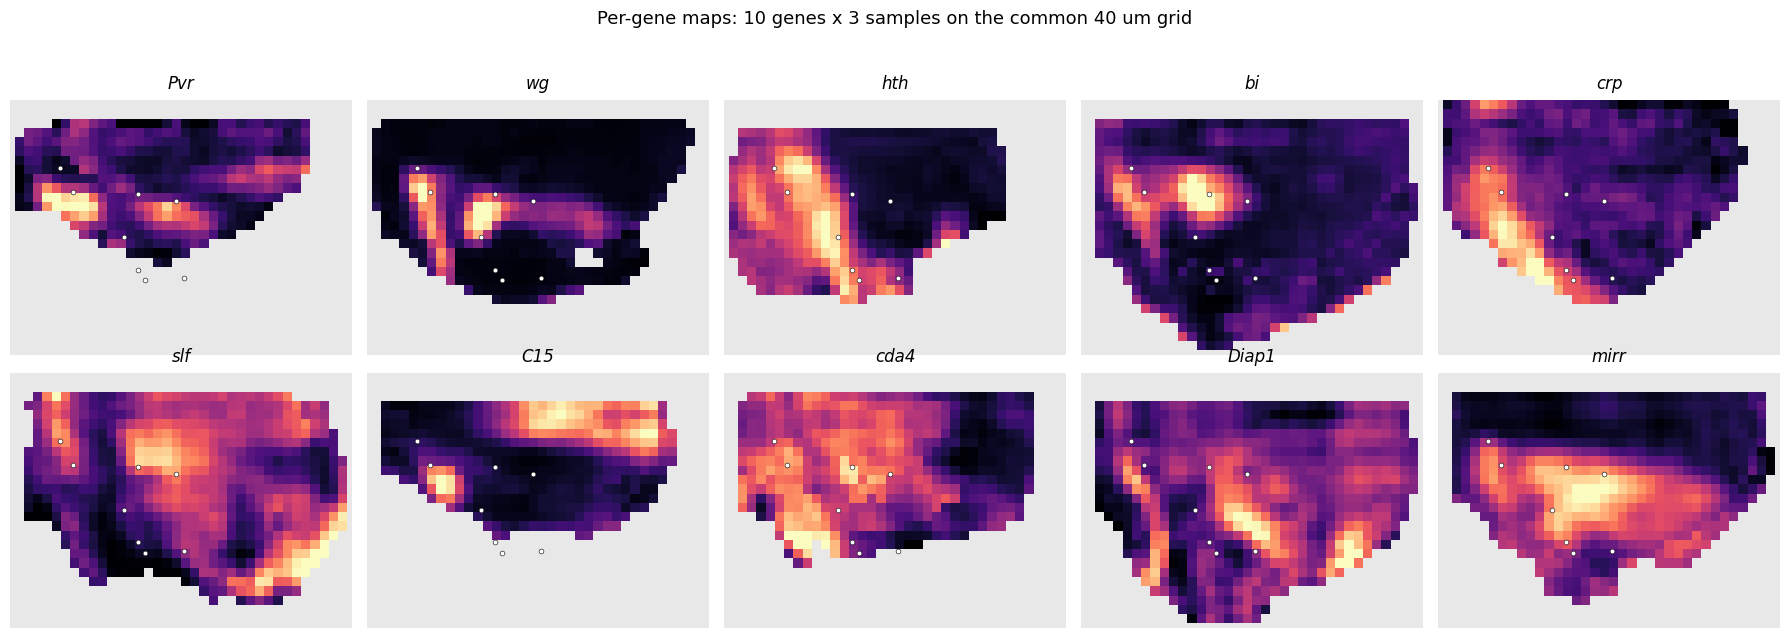

In [11]:
macro = np.loadtxt(MACROCHAETE, delimiter=",")   # row 0: coordY units, row 1: coordX units
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("#e8e8e8")

# maps are drawn transposed, so screen x is coordY and screen y is coordX; frame on the tissue
iy, ix = np.where(np.any([~np.isnan(mean_maps[gene]) for gene in GENES], axis=0))
xlim, ylim = (iy.min() - 1, iy.max() + 1), (ix.max() + 1, ix.min() - 1)

fig, axes = plt.subplots(2, 5, figsize=(18, 6.6))
for ax, gene in zip(axes.ravel(), GENES):
    m = mean_maps[gene]
    ax.imshow(m.T, cmap=cmap, vmin=0, vmax=np.nanpercentile(m, 99), interpolation="nearest")
    ax.scatter(macro[0] - 1, macro[1] - 1, s=12, facecolor="white", edgecolor="black", lw=0.4)
    ax.set_title(gene, fontsize=12, style="italic")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.axis("off")
fig.suptitle(f"Per-gene maps: {len(GENES)} genes x {SAMPLES_PER_GENE} samples on the common 40 um grid", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 9. The final atlas

Every gene covers a slightly different part of the grid: each sample contributes only the boxes its notum actually reaches, so the per-gene domains differ by field of view and dissection. An atlas is read one box at a time, all genes together, so its domain is the **intersection**: the boxes where every gene has a value.

325 boxes covered by all 10 genes, out of 839 covered by at least one


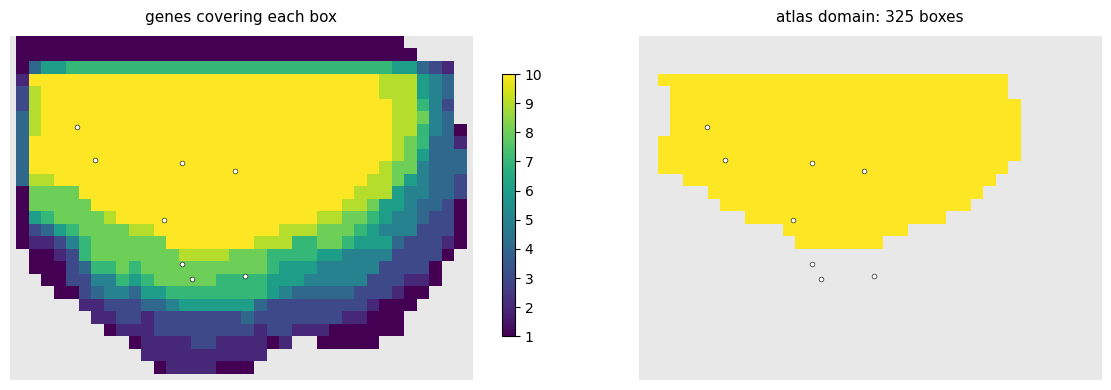

In [12]:
coverage = np.sum([~np.isnan(mean_maps[gene]) for gene in GENES], axis=0)
common = coverage == len(GENES)
print(f"{common.sum()} boxes covered by all {len(GENES)} genes, "
      f"out of {(coverage > 0).sum()} covered by at least one")

cov_cmap = plt.get_cmap("viridis").copy()
cov_cmap.set_bad("#e8e8e8")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(np.where(coverage > 0, coverage, np.nan).T, cmap=cov_cmap,
                    vmin=1, vmax=len(GENES), interpolation="nearest")
axes[0].set_title("genes covering each box", fontsize=11)
fig.colorbar(im, ax=axes[0], shrink=0.75)
axes[1].imshow(np.where(common, len(GENES), np.nan).T, cmap=cov_cmap,
               vmin=1, vmax=len(GENES), interpolation="nearest")
axes[1].set_title(f"atlas domain: {common.sum()} boxes", fontsize=11)
for ax in axes:
    ax.scatter(macro[0] - 1, macro[1] - 1, s=12, facecolor="white", edgecolor="black", lw=0.4)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.axis("off")
fig.tight_layout()
plt.show()

The atlas is one comma-separated table: one row per grid box with `coordX` (1..40, medio-lateral) varying fastest and `coordY` (1..67, anterior-posterior), one column per gene, and `n_nota_gene`, the number of samples behind the box, taken as the minimum over genes and zero outside the common domain. This is the format of the shipped `data/morphology/atlas_validation.txt`, which [vgep](https://github.com/BellaicheLab/vgep) reads to reconstruct a spatial transcriptome: the mask it applies on loading, `n_nota_gene > 0`, selects exactly the domain we just kept.

In [13]:
n_cy, n_cx = mean_maps[GENES[0]].shape

atlas = pd.DataFrame({gene: np.where(common, mean_maps[gene], np.nan).ravel() for gene in GENES})
atlas["n_nota_gene"] = np.where(
    common, np.min(np.stack([n_valid[gene] for gene in GENES]), axis=0), 0).ravel()
atlas["coordX"] = np.tile(np.arange(1, n_cx + 1), n_cy)
atlas["coordY"] = np.repeat(np.arange(1, n_cy + 1), n_cx)
atlas.to_csv(WORK / "atlas.txt", index=False)

print(f"{atlas.shape[0]} rows x {atlas.shape[1]} columns, {common.sum()} of them filled")

2680 rows x 13 columns, 325 of them filled


Read back from disk, every gene column reshapes to a map on the shared domain. This is the atlas:

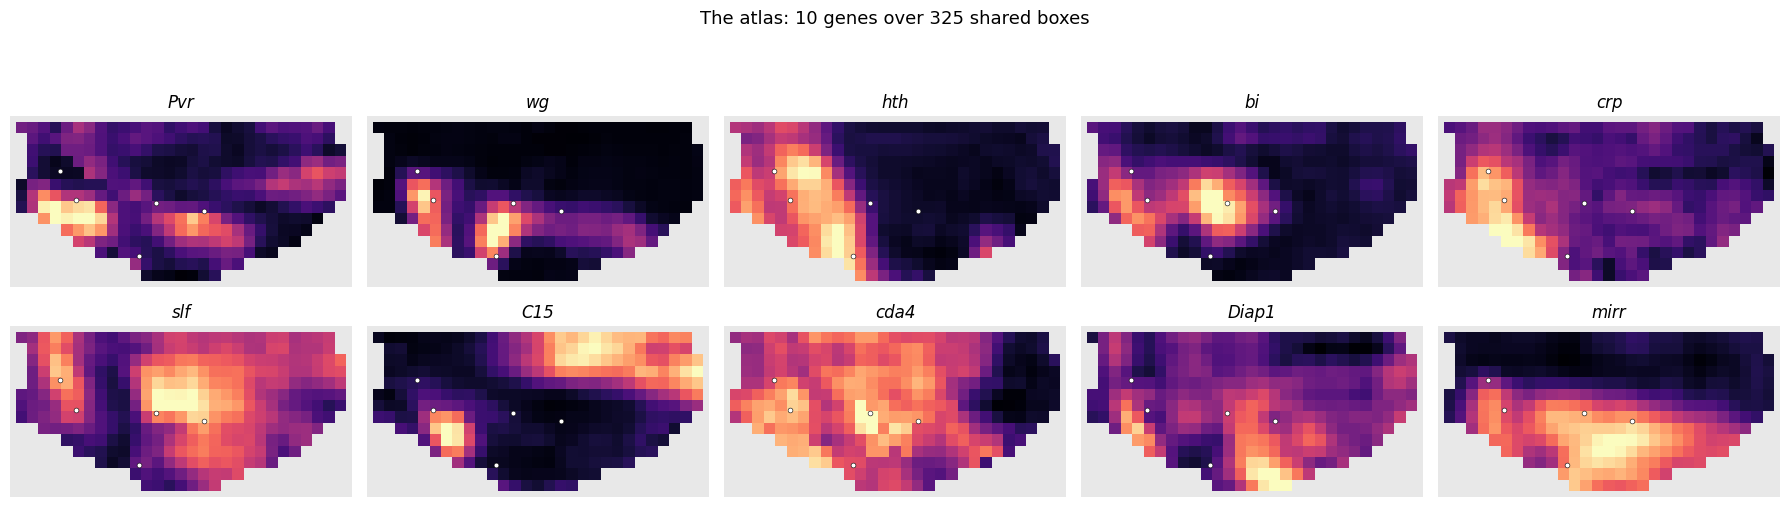

In [14]:
written = pd.read_csv(WORK / "atlas.txt")

iy, ix = np.where(common)
xlim, ylim = (iy.min() - 1, iy.max() + 1), (ix.max() + 1, ix.min() - 1)

fig, axes = plt.subplots(2, 5, figsize=(18, 5.5))
for ax, gene in zip(axes.ravel(), GENES):
    m = written[gene].values.reshape(n_cy, n_cx)
    ax.imshow(m.T, cmap=cmap, vmin=0, vmax=np.nanpercentile(m, 99), interpolation="nearest")
    ax.scatter(macro[0] - 1, macro[1] - 1, s=12, facecolor="white", edgecolor="black", lw=0.4)
    ax.set_title(gene, fontsize=12, style="italic")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.axis("off")
fig.suptitle(f"The atlas: {len(GENES)} genes over {common.sum()} shared boxes", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## Where to go next

- [Atlas walkthrough](../docs/guides/atlas_pipeline.md): the full pipeline, including the MATLAB production route and the vgep hand-off
- [morphodomains notebook 02](https://github.com/BellaicheLab/morphodomains): turning an atlas table like this one into a genome-wide spatial transcriptome
- [01_python_route_basics](01_python_route_basics.ipynb): the same machinery on time-lapse data